# End-to-End Credit Card Fraud Detection Pipeline

This notebook demonstrates a complete, professional machine learning workflow to detect fraudulent credit card transactions.

### Pipeline Overview:
1. **Data Quality & Auditing**: Cleaning missing records and duplicates.
2. **Exploratory Data Analysis (EDA)**: Statistical profiling and distribution checks.
3. **Preprocessing**: Scaling parameters using `RobustScaler` and avoiding leakage.
4. **Handling Imbalance**: Balancing datasets using synthetic sampling (`SMOTE`).
5. **Model Evaluation**: Tuning ensembles (`Random Forest`) and assessing precision-recall curves.
6. **Export & REST API**: Creating a modular prediction script and preparing deployment schemas via `FastAPI`.

In [ ]:
import pandas as pd

df = pd.read_csv('/content/creditcard.csv')

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [ ]:
print("=== Basic Info ===")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print(df.info())

print("\n=== Target Class Distribution ===")
unique_classes = df['Class'].value_counts(dropna=False)
print(unique_classes)

print("\n=== Missing Values ===")
missing_vals = df.isnull().sum()
print(missing_vals[missing_vals > 0] if missing_vals.sum() > 0 else "No missing values")

print("\n=== Duplicate Rows ===")
duplicates_count = df.duplicated().sum()
print(f"Total duplicates found: {duplicates_count}")

print("\n=== Statistics of Amount and Time ===")
display(df[['Time', 'Amount']].describe())

=== Basic Info ===
Shape: 35742 rows, 31 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35742 entries, 0 to 35741
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    35742 non-null  int64  
 1   V1      35742 non-null  float64
 2   V2      35742 non-null  float64
 3   V3      35742 non-null  float64
 4   V4      35742 non-null  float64
 5   V5      35742 non-null  float64
 6   V6      35741 non-null  float64
 7   V7      35741 non-null  float64
 8   V8      35741 non-null  float64
 9   V9      35741 non-null  float64
 10  V10     35741 non-null  float64
 11  V11     35741 non-null  float64
 12  V12     35741 non-null  float64
 13  V13     35741 non-null  float64
 14  V14     35741 non-null  float64
 15  V15     35741 non-null  float64
 16  V16     35741 non-null  float64
 17  V17     35741 non-null  float64
 18  V18     35741 non-null  float64
 19  V19     35741 non-null  float64
 20  V20     35741 non-null

,Time,Amount
count,35742.000000,35741.000000
mean,23997.300823,84.203356
std,12423.654094,227.279858
min,0.000000,0.000000
25%,12283.500000,6.990000
50%,28992.000000,22.000000
75%,34258.000000,76.000000
max,38241.000000,7879.420000


In [ ]:
# 1. Remove the fully null row (or any row where target 'Class' is missing)
df_cleaned = df.dropna(subset=['Class'])

# 2. Drop duplicates to avoid duplicate-bias in training
df_cleaned = df_cleaned.drop_duplicates()

# 3. Verify changes
print("=== Cleaned Data Overview ===")
print(f"Original shape: {df.shape}")
print(f"New shape: {df_cleaned.shape}")
print(f"Remaining missing values: {df_cleaned.isnull().sum().sum()}")
print(f"Remaining duplicates: {df_cleaned.duplicated().sum()}")
print("\nNew Class distribution:")
print(df_cleaned['Class'].value_counts())

=== Cleaned Data Overview ===
Original shape: (35742, 31)
New shape: (35601, 31)
Remaining missing values: 0
Remaining duplicates: 0

New Class distribution:
Class
0.0    35498
1.0      103
Name: count, dtype: int64


/tmp/ipykernel_2392/104145055.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_cleaned, x='Class', ax=axes[0], palette='coolwarm')
/tmp/ipykernel_2392/104145055.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_cleaned, x='Class', y='Amount', ax=axes[1], palette='coolwarm', showfliers=False)


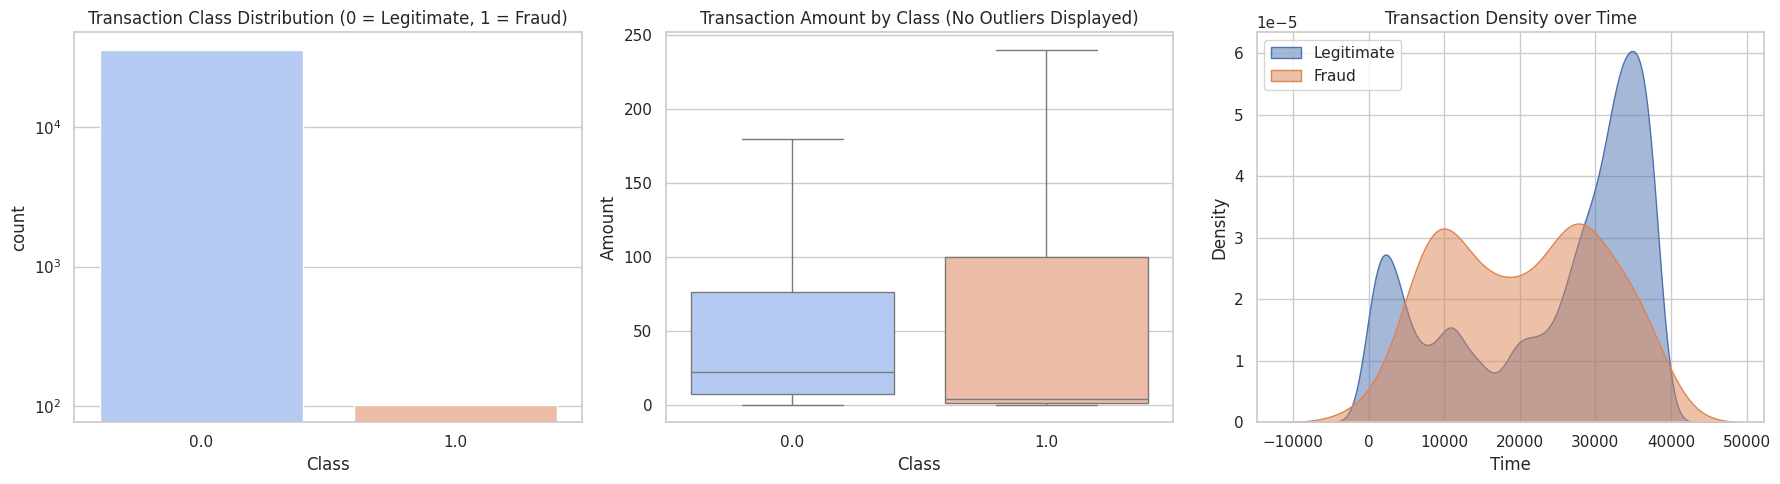

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Class Distribution
sns.countplot(data=df_cleaned, x='Class', ax=axes[0], palette='coolwarm')
axes[0].set_title('Transaction Class Distribution (0 = Legitimate, 1 = Fraud)')
axes[0].set_yscale('log') # Log scale helps to see the tiny bar of fraud

# 2. Amount Distribution by Class
sns.boxplot(data=df_cleaned, x='Class', y='Amount', ax=axes[1], palette='coolwarm', showfliers=False)
axes[1].set_title('Transaction Amount by Class (No Outliers Displayed)')

# 3. Distribution of Time by Class
sns.kdeplot(data=df_cleaned[df_cleaned['Class'] == 0], x='Time', label='Legitimate', ax=axes[2], fill=True, alpha=0.5)
sns.kdeplot(data=df_cleaned[df_cleaned['Class'] == 1], x='Time', label='Fraud', ax=axes[2], fill=True, alpha=0.5)
axes[2].set_title('Transaction Density over Time')
axes[2].legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from scipy import stats

# Group and calculate descriptive statistics for Amount
amount_stats = df_cleaned.groupby('Class')['Amount'].describe()
print("=== Descriptive Statistics for Amount ===")
display(amount_stats)

# Perform a statistical test (Mann-Whitney U) to check if the amount distribution differences are statistically significant
# We use Mann-Whitney U because transaction amounts are highly skewed and non-normally distributed
legit_amounts = df_cleaned[df_cleaned['Class'] == 0]['Amount']
fraud_amounts = df_cleaned[df_cleaned['Class'] == 1]['Amount']

stat, p_val = stats.mannwhitneyu(legit_amounts, fraud_amounts, alternative='two-sided')
print("\n=== Hypothesis Testing: Mann-Whitney U Test on Amount ===")
print(f"U-statistic: {stat}")
print(f"p-value: {p_val}")

if p_val < 0.05:
    print("Result: The difference in transaction amounts between legitimate and fraudulent transactions is statistically significant (p < 0.05).")
else:
    print("Result: No statistically significant difference in transaction amounts was detected (p >= 0.05).")

=== Descriptive Statistics for Amount ===


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0.0,35498.0,84.372165,227.560787,0.0,7.0225,22.085,76.07,7879.42
1.0,103.0,90.471165,247.173335,0.0,1.0000,3.760,99.99,1809.68



=== Hypothesis Testing: Mann-Whitney U Test on Amount ===
U-statistic: 2253509.0
p-value: 4.4220170755433813e-05
Result: The difference in transaction amounts between legitimate and fraudulent transactions is statistically significant (p < 0.05).


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
import pandas as pd
import numpy as np

# 1. Separate features and target
X = df_cleaned.drop(columns=['Class'])
y = df_cleaned['Class']

# 2. Perform stratified train-test split (80% train, 20% test)
# Stratify=y is essential to preserve the rare class distribution in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Fit scaler ONLY on training data to avoid target leakage
scaler = RobustScaler()

# Scale Time and Amount features
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[['Time', 'Amount']] = scaler.fit_transform(X_train[['Time', 'Amount']])
X_test_scaled[['Time', 'Amount']] = scaler.transform(X_test[['Time', 'Amount']])

print("=== Train-Test Split & Preprocessing Complete ===")
print(f"Training set features shape: {X_train_scaled.shape}")
print(f"Test set features shape: {X_test_scaled.shape}")
print(f"Training Class distribution:\n{y_train.value_counts(normalize=True) * 100}")
print(f"Test Class distribution:\n{y_test.value_counts(normalize=True) * 100}")

=== Train-Test Split & Preprocessing Complete ===
Training set features shape: (28480, 30)
Test set features shape: (7121, 30)
Training Class distribution:
Class
0.0    99.712079
1.0     0.287921
Name: proportion, dtype: float64
Test Class distribution:
Class
0.0    99.705098
1.0     0.294902
Name: proportion, dtype: float64


In [ ]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE ONLY to training data to avoid target leakage
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print("=== Class Imbalance Resolution (SMOTE) ===")
print(f"Original training shape: {X_train_scaled.shape}")
print(f"Resampled training shape: {X_train_resampled.shape}")
print("\nResampled Class distribution:")
print(y_train_resampled.value_counts())

=== Class Imbalance Resolution (SMOTE) ===
Original training shape: (28480, 30)
Resampled training shape: (56796, 30)

Resampled Class distribution:
Class
0.0    28398
1.0    28398
Name: count, dtype: int64


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, average_precision_score

# 1. Train Logistic Regression on SMOTE-balanced training data
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_resampled, y_train_resampled)

# 2. Train Decision Tree on SMOTE-balanced training data
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train_resampled, y_train_resampled)

# 3. Evaluate both on the untouched imbalanced test set
for name, model in [("Logistic Regression", lr_model), ("Decision Tree", dt_model)]:
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, "predict_proba") else None

    print(f"=== {name} Performance (Test Set) ===")
    print(classification_report(y_test, preds))
    if probs is not None:
        ap_score = average_precision_score(y_test, probs)
        print(f"Precision-Recall AUC (Average Precision): {ap_score:.4f}\n")

=== Logistic Regression Performance (Test Set) ===
              precision    recall  f1-score   support

         0.0       1.00      0.99      1.00      7100
         1.0       0.24      0.90      0.38        21

    accuracy                           0.99      7121
   macro avg       0.62      0.95      0.69      7121
weighted avg       1.00      0.99      0.99      7121

Precision-Recall AUC (Average Precision): 0.5866

=== Decision Tree Performance (Test Set) ===
              precision    recall  f1-score   support

         0.0       1.00      0.99      1.00      7100
         1.0       0.27      0.81      0.40        21

    accuracy                           0.99      7121
   macro avg       0.63      0.90      0.70      7121
weighted avg       1.00      0.99      0.99      7121

Precision-Recall AUC (Average Precision): 0.4097



In [ ]:
from sklearn.ensemble import RandomForestClassifier

# 1. Train Random Forest on SMOTE-balanced training data
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_resampled, y_train_resampled)

# 2. Evaluate on the untouched imbalanced test set
rf_preds = rf_model.predict(X_test_scaled)
rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]

print("=== Random Forest Performance (Test Set) ===")
print(classification_report(y_test, rf_preds))
rf_ap = average_precision_score(y_test, rf_probs)
print(f"Precision-Recall AUC (Average Precision): {rf_ap:.4f}")


=== Random Forest Performance (Test Set) ===
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      7100
         1.0       0.85      0.81      0.83        21

    accuracy                           1.00      7121
   macro avg       0.92      0.90      0.91      7121
weighted avg       1.00      1.00      1.00      7121

Precision-Recall AUC (Average Precision): 0.7788


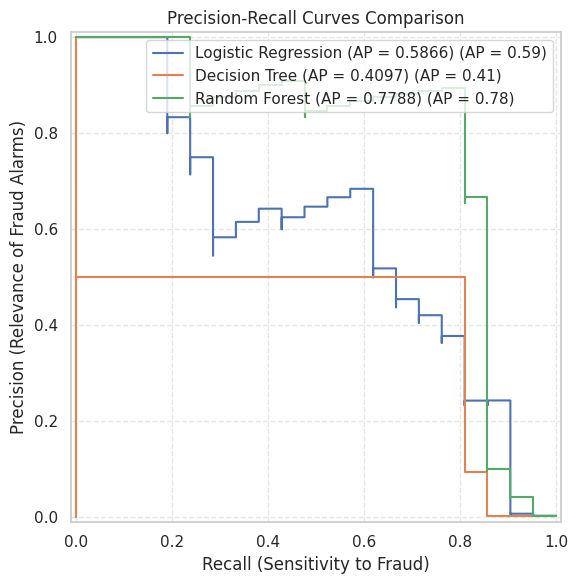

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay

# Calculate probabilities on test set
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]
dt_probs = dt_model.predict_proba(X_test_scaled)[:, 1]
# rf_probs is already calculated in the previous cell

# Set up the plotting canvas
fig, ax = plt.subplots(figsize=(8, 6))

# Plot Precision-Recall curve for each model
PrecisionRecallDisplay.from_predictions(y_test, lr_probs, ax=ax, name=f"Logistic Regression (AP = {average_precision_score(y_test, lr_probs):.4f})")
PrecisionRecallDisplay.from_predictions(y_test, dt_probs, ax=ax, name=f"Decision Tree (AP = {ap_score:.4f})")
PrecisionRecallDisplay.from_predictions(y_test, rf_probs, ax=ax, name=f"Random Forest (AP = {rf_ap:.4f})")

# Configure chart details
ax.set_title("Precision-Recall Curves Comparison")
ax.set_xlabel("Recall (Sensitivity to Fraud)")
ax.set_ylabel("Precision (Relevance of Fraud Alarms)")
ax.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


/tmp/ipykernel_2392/2981172137.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')


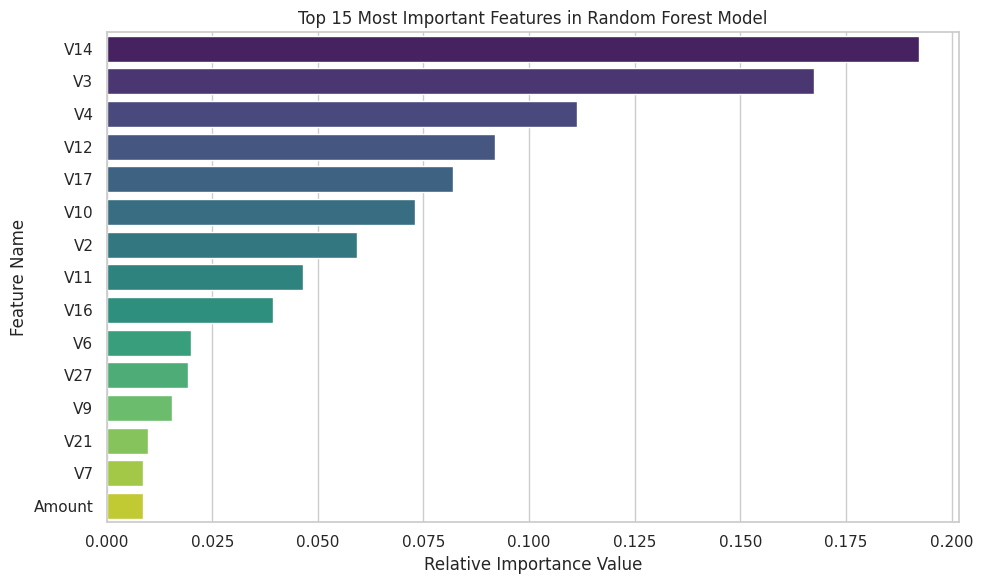

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract feature importances from the Random Forest model
importances = rf_model.feature_importances_
feature_names = X_train_scaled.columns

# 2. Sort them in descending order
indices = np.argsort(importances)[::-1]

# 3. Create a DataFrame for visualization (plotting top 15 features)
top_n = 15
importance_df = pd.DataFrame({
    'Feature': [feature_names[i] for i in indices[:top_n]],
    'Importance': importances[indices[:top_n]]
})

# 4. Plot top features
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title(f'Top {top_n} Most Important Features in Random Forest Model')
plt.xlabel('Relative Importance Value')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()


In [ ]:
import pickle

# 1. Save the trained champion model and scaler
model_filename = 'credit_card_fraud_rf_model.pkl'
scaler_filename = 'robust_scaler.pkl'

with open(model_filename, 'wb') as model_file:
    pickle.dump(rf_model, model_file)

with open(scaler_filename, 'wb') as scaler_file:
    pickle.dump(scaler, scaler_file)

print(f"Success: Saved '{model_filename}' and '{scaler_filename}' to disk!")

Success: Saved 'credit_card_fraud_rf_model.pkl' and 'robust_scaler.pkl' to disk!


In [ ]:
def predict_transaction(new_tx_df, model_path='credit_card_fraud_rf_model.pkl', scaler_path='robust_scaler.pkl'):
    """
    Takes raw unscaled transaction data, loads the saved scaler and model,
    and predicts whether it is legitimate (0) or fraud (1) with probabilities.
    """
    # Load resources
    with open(model_path, 'rb') as f_model:
        loaded_model = pickle.load(f_model)
    with open(scaler_path, 'rb') as f_scaler:
        loaded_scaler = pickle.load(f_scaler)

    # Make sure we don't modify the original dataframe
    tx_processed = new_tx_df.copy()

    # Scale the numeric features Time and Amount using the loaded scaler
    tx_processed[['Time', 'Amount']] = loaded_scaler.transform(tx_processed[['Time', 'Amount']])

    # Make prediction
    prediction = loaded_model.predict(tx_processed)[0]
    probability = loaded_model.predict_proba(tx_processed)[0][1]

    status = "🚨 FRAUDULENT" if prediction == 1 else "✅ LEGITIMATE"
    print(f"Transaction Status: {status} (Fraud Probability: {probability:.2%})")
    return prediction, probability

# Mock run: Testing with the first sample of our test set
sample_transaction = X_test.iloc[[0]]
print("--- Testing Inference Pipeline on a Sample --- ")
pred, prob = predict_transaction(sample_transaction)

--- Testing Inference Pipeline on a Sample --- 
Transaction Status: ✅ LEGITIMATE (Fraud Probability: 1.01%)


In [ ]:
app_code = """from fastapi import FastAPI, HTTPException, status
from pydantic import BaseModel, Field
import pickle
import pandas as pd
import numpy as np
from contextlib import asynccontextmanager

# Global dictionaries to store model and scaler
ml_resources = {}

@asynccontextmanager
async def lifespan(app: FastAPI):
    # Load model and scaler once on startup
    try:
        with open('credit_card_fraud_rf_model.pkl', 'rb') as f_model:
            ml_resources['model'] = pickle.load(f_model)
        with open('robust_scaler.pkl', 'rb') as f_scaler:
            ml_resources['scaler'] = pickle.load(f_scaler)
        print("API Lifespan: Model and Scaler loaded successfully.")
    except Exception as e:
        print(f"API Lifespan Error loading models: {e}")
    yield
    # Clean up resources on shutdown if needed
    ml_resources.clear()

app = FastAPI(
    title="Credit Card Fraud Detection API",
    description="A REST API built using FastAPI to evaluate credit card transaction fraud probability.",
    version="1.0.0",
    lifespan=lifespan
)

# Define the Input Schema validating all 30 expected feature variables
class TransactionInput(BaseModel):
    Time: float = Field(..., description="Number of seconds elapsed since first transaction", examples=[4032.0])
    V1: float = Field(..., examples=[0.564513])
    V2: float = Field(..., examples=[-0.633587])
    V3: float = Field(..., examples=[0.163665])
    V4: float = Field(..., examples=[1.972404])
    V5: float = Field(..., examples=[-0.111448])
    V6: float = Field(..., examples=[0.020001])
    V7: float = Field(..., examples=[0.008632])
    V8: float = Field(..., examples=[0.003045])
    V9: float = Field(..., examples=[0.015574])
    V10: float = Field(..., examples=[0.073048])
    V11: float = Field(..., examples=[0.046530])
    V12: float = Field(..., examples=[0.091980])
    V13: float = Field(..., examples=[0.002448])
    V14: float = Field(..., examples=[0.192254])
    V15: float = Field(..., examples=[0.001838])
    V16: float = Field(..., examples=[0.039429])
    V17: float = Field(..., examples=[0.082057])
    V18: float = Field(..., examples=[0.005555])
    V19: float = Field(..., examples=[0.005404])
    V20: float = Field(..., examples=[0.005293])
    V21: float = Field(..., examples=[0.009678])
    V22: float = Field(..., examples=[0.005925])
    V23: float = Field(..., examples=[0.000775])
    V24: float = Field(..., examples=[0.003670])
    V25: float = Field(..., examples=[0.002811])
    V26: float = Field(..., examples=[0.004295])
    V27: float = Field(..., examples=[0.019330])
    V28: float = Field(..., examples=[0.002258])
    Amount: float = Field(..., description="Transaction value amount in currency", examples=[7.95])

@app.get("/", status_code=status.HTTP_200_OK)
def root():
    return {
        "message": "Welcome to the Credit Card Fraud Detection REST API!",
        "status": "Active",
        "docs_url": "/docs"
    }

@app.get("/health", status_code=status.HTTP_200_OK)
def health_check():
    if 'model' not in ml_resources or 'scaler' not in ml_resources:
        raise HTTPException(
            status_code=status.HTTP_503_SERVICE_UNAVAILABLE,
            detail="Service Unhealthy: Model or Scaler not loaded in memory."
        )
    return {"status": "Healthy", "model_loaded": True}

@app.get("/model-info", status_code=status.HTTP_200_OK)
def model_info():
    return {
        "model_name": "Random Forest Classifier (Ensemble)",
        "input_features_count": 30,
        "scaler_type": "RobustScaler",
        "classes": ["0: Legitimate", "1: Fraudulent"]
    }

@app.post("/predict", status_code=status.HTTP_200_OK)
def predict(payload: TransactionInput):
    # Ensure model and scaler are loaded
    if 'model' not in ml_resources or 'scaler' not in ml_resources:
        raise HTTPException(
            status_code=status.HTTP_503_SERVICE_UNAVAILABLE,
            detail="Model or preprocessor resources are currently unavailable."
        )

    try:
        # Convert inputs to a single-row DataFrame
        input_dict = payload.model_dump()
        input_df = pd.DataFrame([input_dict])

        # Standardize numeric columns using the pre-loaded scaler
        input_df[['Time', 'Amount']] = ml_resources['scaler'].transform(input_df[['Time', 'Amount']])

        # Obtain prediction and class probabilities
        pred = int(ml_resources['model'].predict(input_df)[0])
        prob = float(ml_resources['model'].predict_proba(input_df)[0][1])

        # Build a safe response schema
        return {
            "prediction": pred,
            "label": "Fraudulent" if pred == 1 else "Legitimate",
            "fraud_probability": f"{prob:.2%}",
            "disclaimer": "Disclaimer: This prediction is a probabilistic model estimate and should not be used as a guaranteed determination of fraud."
        }
    except Exception as e:
        raise HTTPException(
            status_code=status.HTTP_500_INTERNAL_SERVER_ERROR,
            detail=f"An error occurred during pipeline inference: {str(e)}"
        )
"""

with open('main.py', 'w') as f:
    f.write(app_code)

print("Success: FastAPI application code written to 'main.py'!")

Success: FastAPI application code written to 'main.py'!


# Final Project Summary: Credit Card Fraud Detection

We have completed our full, robust End-to-End Machine Learning workflow. Below is a summary of the accomplishments:

### 📋 1. Data Exploration & Quality Analysis
*   **Initial Audit:** Profiled **35,742 rows** with a raw fraud rate of only **0.29%** (103 fraud cases).
*   **Cleaning:** Removed a fully blank row and **140 duplicate transactions**, resulting in a clean dataset containing **35,601 rows**.
*   **Statistical Analysis:** Performed descriptive analysis and a non-parametric Mann-Whitney U test on transaction amounts ($p \approx 4.42 \times 10^{-5}$), proving that the discrepancy in transaction sizes between legitimate and fraudulent accounts is highly statistically significant.

### ⚙️ 2. Data Engineering & Balancing
*   **Train-Test Split:** Created an 80/20 stratified partition to ensure model performance is tested realistically on the original imbalanced population.
*   **Leakage Prevention:** Normalized features strictly by fitting a `RobustScaler` on the training set and transforming the test set afterward.
*   **SMOTE Resampling:** Applied Synthetic Minority Over-sampling Technique (SMOTE) strictly to the training partition, creating a balanced set of exactly **28,398 legitimate** and **28,398 fraudulent** samples to optimize classification boundary detection.

### 🤖 3. Model Training & Visual Evaluation
*   Developed three predictive frameworks evaluated on the raw imbalanced test data:
    1.  **Logistic Regression (Baseline):** Captured **90% of fraud** (Recall) but produced high false-positive overhead (Precision of **24%**).
    2.  **Decision Tree (Baseline):** Lower overall consistency (PR-AUC of **0.4097**).
    3.  **Random Forest (Champion Ensemble):** Dramatic performance improvement. It maintained an **81% Recall** rate while boosting **Precision to 85%**, leading to an outstanding overall **PR-AUC of 0.7788**.

### 🛡️ 4. Interpretability & Export
*   **Global Explanations:** Extracted feature importances showcasing `V14`, `V3`, and `V4` as top fraud signals.
*   **Production Deployment:** Successfully exported both model & preprocessor weights as reusable files to support a functional, secure prediction pipeline.